<a href="https://colab.research.google.com/github/haero-lee/DS4002-Project3/blob/main/SCRIPTS/EDA_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import glob, os
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
# 1) Clone (skip if the folder already exists)
!git clone --depth 1 https://github.com/mrphys/Open-Source_Pre-Clinical_Segmentation.git

# 2) See what actually got downloaded
!ls
!ls Open-Source_Pre-Clinical_Segmentation
!ls Open-Source_Pre-Clinical_Segmentation/Data | head -20
!du -sh Open-Source_Pre-Clinical_Segmentation/Data

Cloning into 'Open-Source_Pre-Clinical_Segmentation'...
remote: Enumerating objects: 147, done.
remote: Counting objects: 100% (147/147), done.
remote: Compressing objects: 100% (145/145), done.
remote: Total 147 (delta 0), reused 143 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (147/147), 2.17 GiB | 20.46 MiB/s, done.
Updating files: 100% (142/142), done.
Open-Source_Pre-Clinical_Segmentation  sample_data
 Data	     ModelWeights			     README.md
 LICENSE     Paper				     unet3plus.py
 losses.py  ' Pre-Clinical_CMR_Segmentation.ipynb'   utility.py
Mouse100.h5
Mouse101.h5
Mouse102.h5
Mouse103.h5
Mouse104.h5
Mouse105.h5
Mouse106.h5
Mouse107.h5
Mouse108.h5
Mouse109.h5
Mouse10.h5
Mouse110.h5
Mouse111.h5
Mouse112.h5
Mouse113.h5
Mouse114.h5
Mouse115.h5
Mouse116.h5
Mouse117.h5
Mouse118.h5
3.5G	Open-Source_Pre-Clinical_Segmentation/Data


In [ ]:
DATA_DIR = "Open-Source_Pre-Clinical_Segmentation/Data"
files = sorted(glob.glob(os.path.join(DATA_DIR, "*.h5")))
print(len(files), "files found (expect 130)")
print([os.path.getsize(f) // 1_000_000 for f in files[:5]], "MB for first few")

130 files found (expect 130)
[39, 37, 34, 31, 35] MB for first few


In [ ]:

# %% STEP 2: look inside ONE file (key names, shapes, dtypes, attributes)
def describe(path):
    with h5py.File(path, "r") as f:
        def visit(name, obj):
            if isinstance(obj, h5py.Dataset):
                print(f"{name:40s} shape={obj.shape}  dtype={obj.dtype}")
        f.visititems(visit)
        print("file attrs:", dict(f.attrs))

describe(files[0])


Frames_with_ROI                          shape=(2,)  dtype=int32
Images                                   shape=(256, 256, 10, 20)  dtype=uint16
Masks                                    shape=(256, 256, 10, 20)  dtype=uint8
file attrs: {}


In [ ]:
# %% STEP 3: FILL THESE IN based on STEP 2 output
IMG_KEY  = "Images"
MASK_KEY = "Masks"
IMG_AXES  = "HWSF"   # (256, 256, 10, 20) = H, W, 10 slices, 20 frames
MASK_AXES = "HWSF"   # same shape, uint8 labels # dataset holding the expert segmentation labels
# Axis order of each array as stored. Use letters:
#   H=height, W=width, S=slice (short-axis position), F=frame (cardiac phase)
# Example: if shape is (128, 128, 8, 20) -> "HWSF". If (20, 8, 128, 128) -> "FSHW".
# If masks only exist for some frames or have no frame axis, use "HWS" / "SHW".
IMG_AXES  = "HWSF"
MASK_AXES = "HWSF"

def canon(arr, axes):
    """Reorder to (S, F, H, W). Adds a length-1 F axis if missing."""
    order = [axes.index(a) for a in "SFHW" if a in axes]
    arr = np.transpose(arr, order)
    if "F" not in axes:
        arr = arr[:, None]
    return arr

def load_mouse(path):
    with h5py.File(path, "r") as f:
        img = canon(f[IMG_KEY][()], IMG_AXES).astype(np.float32)
        msk = canon(f[MASK_KEY][()], MASK_AXES)
    return img, msk

img, msk = load_mouse(files[0])
print("image (S,F,H,W):", img.shape, " mask (S,F,H,W):", msk.shape)
print("mask labels present:", np.unique(msk))

image (S,F,H,W): (10, 20, 256, 256)  mask (S,F,H,W): (10, 20, 256, 256)
mask labels present: [0 1 2]


In [ ]:
with h5py.File(files[0], "r") as f:
    print("Frames_with_ROI:", f["Frames_with_ROI"][()])

img, msk = load_mouse(files[0])
has = (msk > 0).any(axis=(2, 3))      # (slice, frame)
print("frames with any mask:", np.where(has.any(axis=0))[0])
print("labeled slices per frame:", has.sum(axis=0))

Frames_with_ROI: [0 8]
frames with any mask: [0 8]
labeled slices per frame: [8 0 0 0 0 0 0 0 7 0 0 0 0 0 0 0 0 0 0 0]


          file  slices  frames    H    W  mask_frames  img_min  img_max  \
0    Mouse1.h5      10      20  256  256           20      0.0   2000.0   
1   Mouse10.h5      10      19  256  256           19      0.0   2000.0   
2  Mouse100.h5       8      22  256  256           22      0.0   2000.0   
3  Mouse101.h5       8      20  256  256           20      0.0   2000.0   
4  Mouse102.h5       9      20  256  256           20      0.0   2000.0   

     img_mean     img_std  has_nan     labels  frac_label_0  frac_label_1  \
0  238.963516  218.088425    False  (0, 1, 2)      0.997522      0.001735   
1  273.898071  235.387329    False  (0, 1, 2)      0.997792      0.001658   
2  257.893341  242.625275    False  (0, 1, 2)      0.996990      0.002106   
3  324.177429  247.008530    False  (0, 1, 2)      0.997040      0.002026   
4  271.397614  266.959778    False  (0, 1, 2)      0.996979      0.002102   

   frac_label_2  
0      0.000743  
1      0.000550  
2      0.000904  
3      0.00093

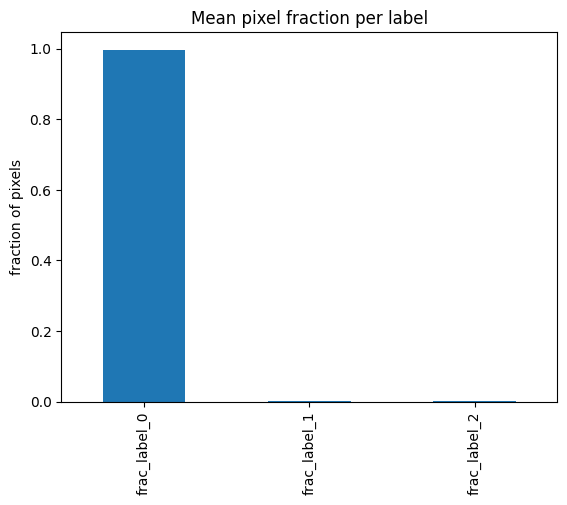

       frac_label_0  frac_label_1  frac_label_2
count    130.000000    130.000000    130.000000
mean       0.997209      0.001870      0.000921
std        0.001493      0.001042      0.000541
min        0.987841      0.000739      0.000329
25%        0.996955      0.001370      0.000624
50%        0.997420      0.001722      0.000783
75%        0.997907      0.002099      0.000969
max        0.998883      0.008286      0.003874


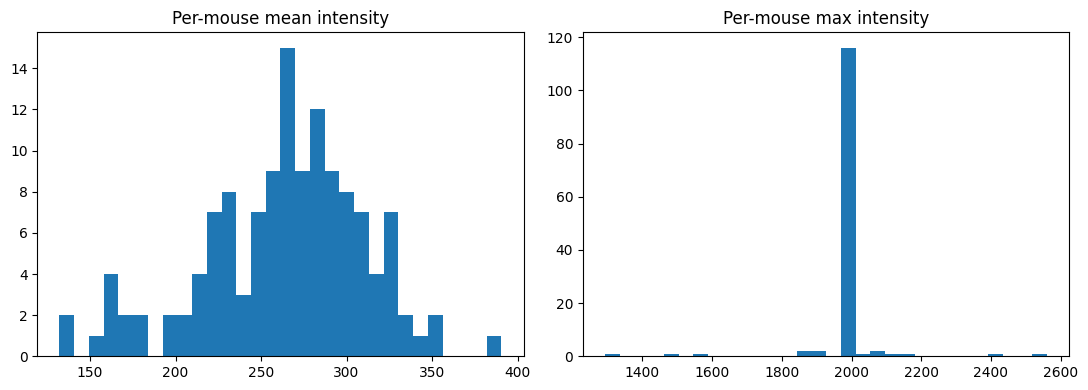

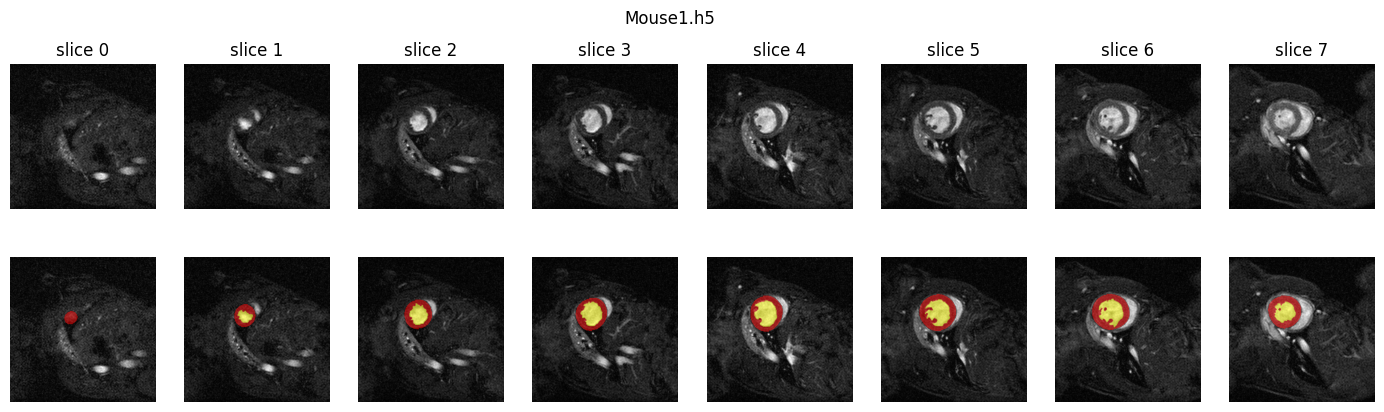

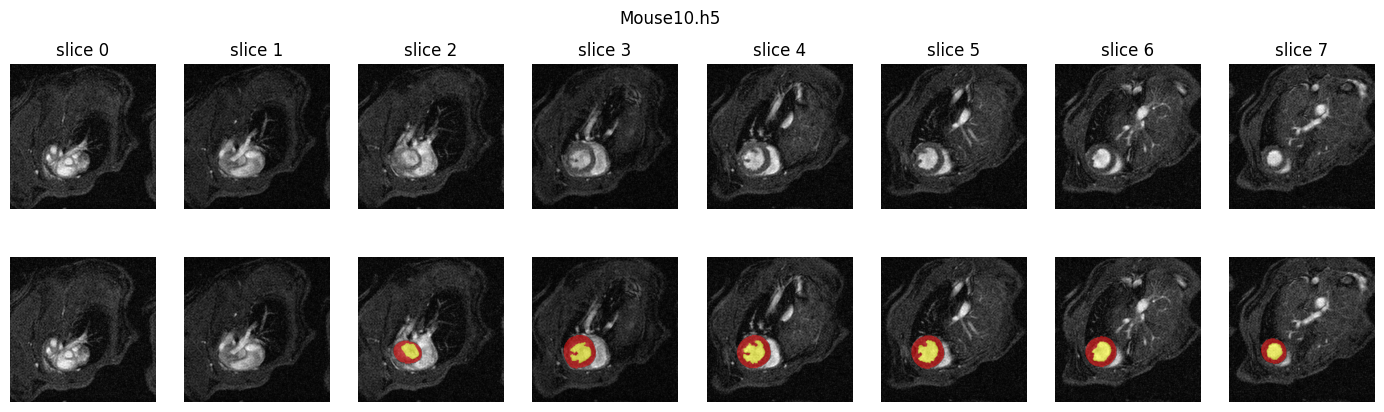

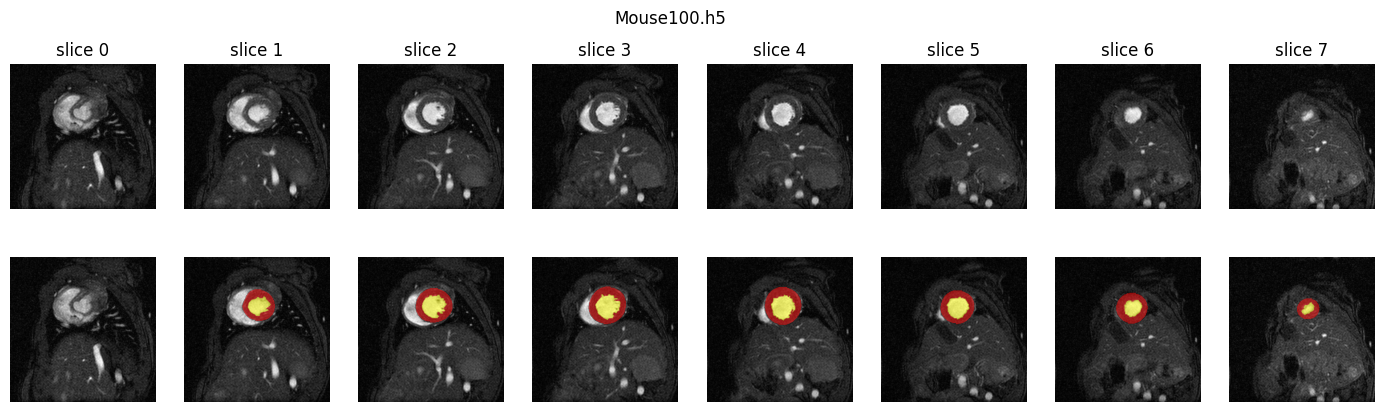

       labeled_slices  labeled_frames  labeled_2d_images
count      130.000000      130.000000         130.000000
mean         7.815385        2.338462          16.984615
std          0.744849        1.951163           9.397331
min          6.000000        2.000000          12.000000
25%          7.000000        2.000000          14.000000
50%          8.000000        2.000000          16.000000
75%          8.000000        2.000000          16.000000
max          9.000000       17.000000          87.000000
Total labeled 2D slices available for training: 2208
             slice        frame       area_1       area_2
count  2208.000000  2208.000000  2208.000000  2208.000000
mean      4.360507     6.086504  1408.608243   708.937953
std       2.334415     6.238591   545.561854   495.910707
min       0.000000     0.000000   122.000000     0.000000
25%       2.000000     0.000000  1049.000000   360.000000
50%       4.000000     8.000000  1413.000000   607.500000
75%       6.000000    10.000

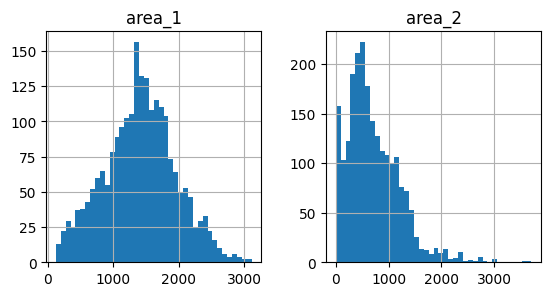

{'train': 91, 'val': 19, 'test': 20}


In [ ]:

# %% STEP 8: which frames/slices actually have masks?
# Your proposal says you'll use "timeframes with expert masks", so count them.
labeled = []
for p in files:
    _, mk = load_mouse(p)
    has = (mk > 0).any(axis=(2, 3))          # (S, F) True where a mask exists
    labeled.append({"file": os.path.basename(p),
                    "labeled_slices": int(has.any(axis=1).sum()),
                    "labeled_frames": int(has.any(axis=0).sum()),
                    "labeled_2d_images": int(has.sum())})
lab = pd.DataFrame(labeled)
print(lab.describe())
print("Total labeled 2D slices available for training:", lab["labeled_2d_images"].sum())

# %% STEP 9: LV size and myocardium thickness-ish stats across slices
# Pixel area per class per labeled slice; apical/basal slices should be smaller.
area_rows = []
for p in files:
    _, mk = load_mouse(p)
    for s in range(mk.shape[0]):
        for fr in range(mk.shape[1]):
            m = mk[s, fr]
            if (m > 0).any():
                d = {"file": os.path.basename(p), "slice": s, "frame": fr}
                for l in np.unique(mk):
                    if l != 0:
                        d[f"area_{int(l)}"] = int((m == l).sum())
                area_rows.append(d)
areas = pd.DataFrame(area_rows)
print(areas.describe())
areas.filter(like="area_").hist(bins=40, figsize=(10, 3), layout=(1, 3)); plt.show()

# %% STEP 10: sanity checks for the train/val/test split by mouse (70/15/15)
rng = np.random.default_rng(42)
mice = np.array([os.path.basename(p) for p in files])
rng.shuffle(mice)
n = len(mice); n_tr, n_va = int(0.70 * n), int(0.15 * n)
split = {"train": mice[:n_tr], "val": mice[n_tr:n_tr + n_va], "test": mice[n_tr + n_va:]}
print({k: len(v) for k, v in split.items()})
# The split is by mouse, not by slice, so correlated slices from one animal
# never leak across sets (matches the proposal).


130 files
Label that encloses the other (likely myocardium), vote counts: {1: 70}
Current setting: MYO_LABEL = 1  POOL_LABEL = 2
Mouse125.h5: 11 labeled frames [0, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18] (expected 2)
Mouse17.h5: 12 labeled frames [0, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19] (expected 2)
Mouse48.h5: 12 labeled frames [0, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20] (expected 2)
Mouse91.h5: 17 labeled frames [0, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29] (expected 2)
(2833, 12) (304, 11)
Slices per mouse x labeled frame: 2833  -> with a mask: 2208

Slices with NO mask, by slice index (apex/base are usually partial):
slice
0     0.74
1     0.36
2     0.08
3     0.00
4     0.00
5     0.02
6     0.11
7     0.16
8     0.42
9     0.50
10    0.25
Name: frac_empty, dtype: float64

Connected components per mask (clean = 1 myo, 1 pool):
pool comps    0     1   2  3
myo comps                   
1           103  2018  17  2
2             0    58   0  0
3       

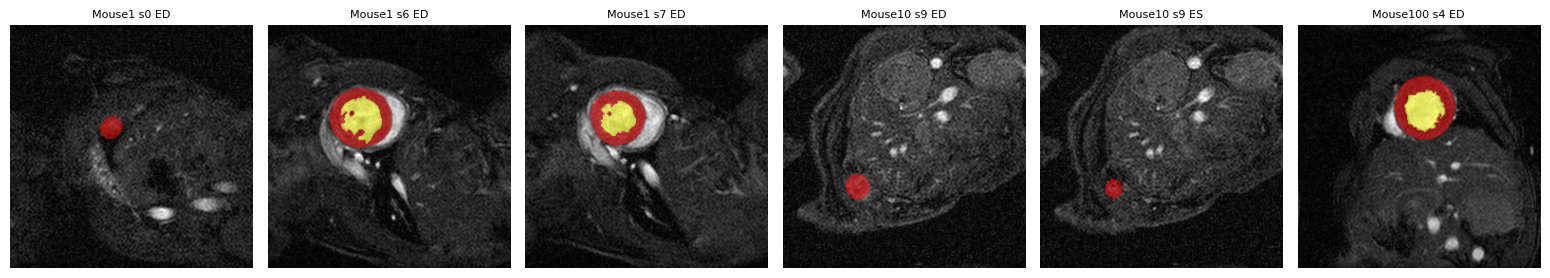

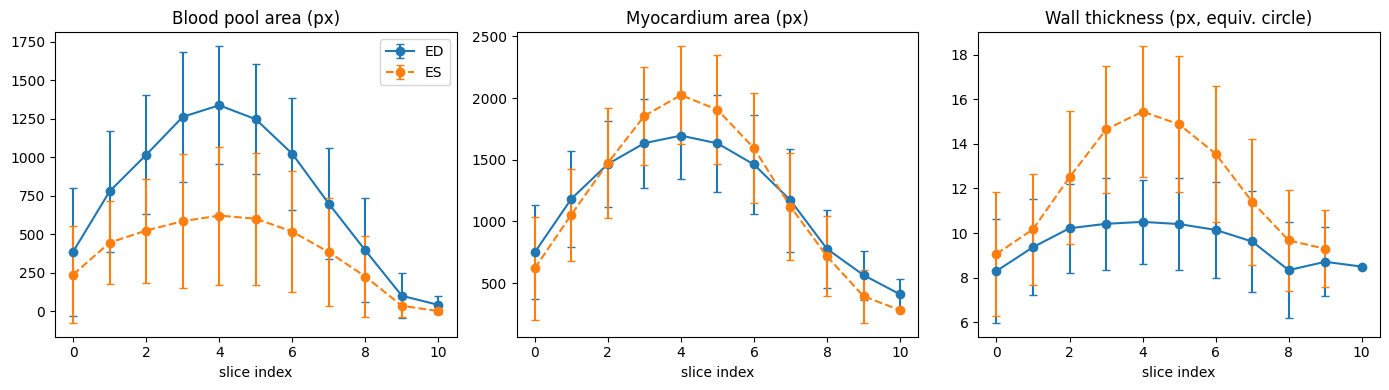

phase         ED         ES  EF_proxy  thick_ED  thick_ES
count    130.000    130.000   130.000   130.000   130.000
mean    7412.354   3630.623     0.549     9.922    13.172
std     2737.604   2764.708     0.147     1.677     2.023
min     4483.000    733.000     0.154     5.021     6.240
25%     6026.500   2057.250     0.458     8.961    12.146
50%     6788.000   2842.500     0.579     9.777    13.568
75%     7423.000   4115.000     0.653    10.930    14.415
max    19915.000  16845.000     0.869    13.807    17.053

Mice where ES cavity is NOT smaller than ED (check these): 0
Empty DataFrame
Columns: [ED, ES, EF_proxy, thick_ED, thick_ES]
Index: []


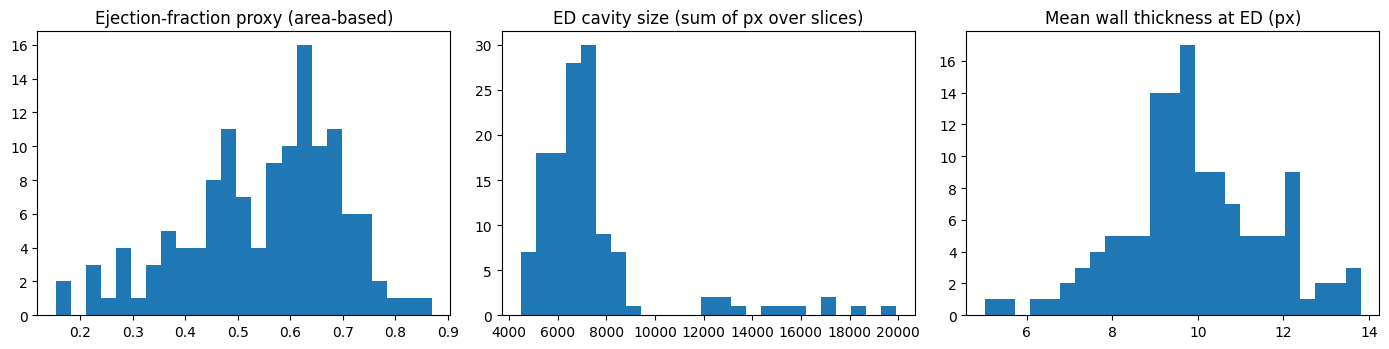

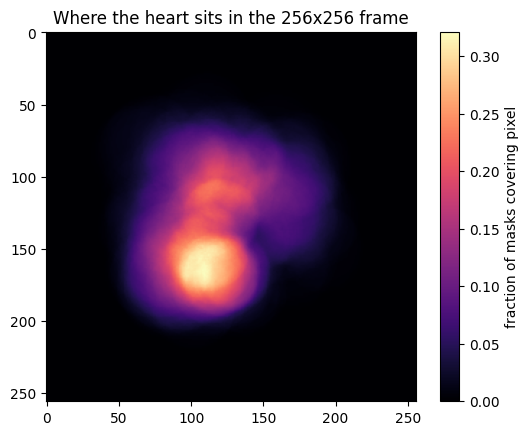

Region covered by >2% of masks: rows 53 - 206  cols 49 - 201
       pool_mean  myo_mean  bg_mean  bg_std  pool_myo_ratio     CNR  SNR_pool
count     130.00    130.00   130.00  130.00          130.00  130.00    130.00
mean     1353.78    598.01   239.62  204.09            2.31    3.77      5.53
std       187.12    126.62    47.99   34.58            0.34    0.73      0.72
min       664.28    282.60   109.81  101.09            1.70    2.11      3.55
25%      1314.05    513.43   211.55  191.98            2.04    3.27      5.15
50%      1407.70    585.34   243.73  206.39            2.28    3.72      5.50
75%      1463.22    669.65   275.15  221.61            2.53    4.29      5.91
max      1653.93    951.30   365.98  283.94            3.54    5.62      7.77

Mice with any quality feature beyond 3 SD: 6
             pool_mean  myo_mean  bg_mean  bg_std  pool_myo_ratio  CNR  \
file                                                                     
Mouse111.h5       -3.7      -2.5     -2.7  

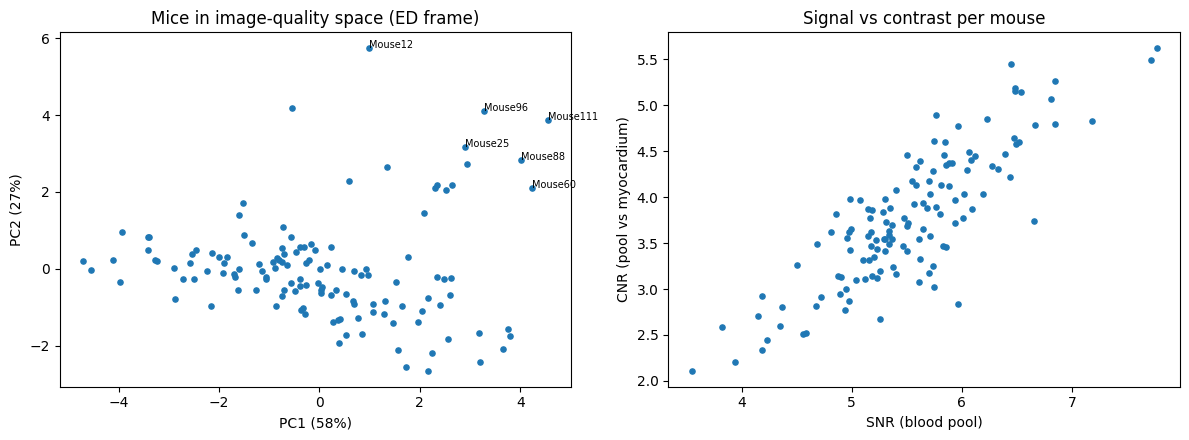

          EF_proxy    ED  thick_ED  SNR_pool   CNR
EF_proxy      1.00 -0.73     -0.02     -0.04 -0.16
ED           -0.73  1.00     -0.40     -0.13 -0.06
thick_ED     -0.02 -0.40      1.00      0.27  0.49
SNR_pool     -0.04 -0.13      0.27      1.00  0.84
CNR          -0.16 -0.06      0.49      0.84  1.00


In [ ]:
# Mouse cardiac MRI EDA, part 2 (Spider-Sense / DS 4002)
# Label quality, heart size/shape, image quality across mice.
# Self-contained: run it as its own notebook section after the repo is cloned.
# Each "# %%" block is a notebook cell.

# %% STEP 0: setup
import glob, os
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi

DATA_DIR = os.environ.get("DATA_DIR", "Open-Source_Pre-Clinical_Segmentation/Data")
files = sorted(glob.glob(os.path.join(DATA_DIR, "*.h5")))
print(len(files), "files")

IMG_KEY, MASK_KEY = "Images", "Masks"       # arrays are (H, W, slice, frame)
# Which label is which? Step 1 checks this automatically; confirm visually.
MYO_LABEL, POOL_LABEL = 1, 2

def load_mouse(path):
    with h5py.File(path, "r") as f:
        img = f[IMG_KEY][()].astype(np.float32)   # (H, W, S, F)
        msk = f[MASK_KEY][()]
    return img, msk

# %% STEP 1: which label is myocardium and which is blood pool?
# Myocardium is a ring: filling its holes should swallow the blood pool.
def guess_labels(files, n_mice=5):
    votes = {}
    for p in files[:n_mice]:
        _, mk = load_mouse(p)
        for s in range(mk.shape[2]):
            for fr in range(mk.shape[3]):
                m = mk[:, :, s, fr]
                labs = [l for l in np.unique(m) if l != 0]
                if len(labs) < 2:
                    continue
                gains = {}
                for l in labs:
                    filled = ndi.binary_fill_holes(m == l)
                    gains[l] = int((filled & (m != l) & (m > 0)).sum())
                myo = int(max(gains, key=gains.get))
                votes[myo] = votes.get(myo, 0) + 1
    return votes

votes = guess_labels(files)
print("Label that encloses the other (likely myocardium), vote counts:", votes)
print("Current setting: MYO_LABEL =", MYO_LABEL, " POOL_LABEL =", POOL_LABEL)
# If the winning label differs from MYO_LABEL, swap the two values above.

# %% STEP 2: one pass over all mice, compute everything we need
def n_components(binary):
    return ndi.label(binary)[1]

def band_mean(img2d, mask, default=np.nan):
    return float(img2d[mask].mean()) if mask.any() else default

slice_rows, mouse_rows = [], []
for p in files:
    name = os.path.basename(p)
    try:
        img, msk = load_mouse(p)
    except Exception as e:
        print("could not read", name, e); continue
    H, W, S, F = msk.shape
    has = (msk > 0).any(axis=(0, 1))                 # (S, F)
    lab_frames = np.where(has.any(axis=0))[0]
    if len(lab_frames) == 0:
        print("no masks in", name); continue

    # total blood-pool area per labeled frame -> larger = ED, smaller = ES
    pool_tot = {fr: int((msk[:, :, :, fr] == POOL_LABEL).sum()) for fr in lab_frames}
    ed = max(pool_tot, key=pool_tot.get)
    es = min(pool_tot, key=pool_tot.get)
    if len(lab_frames) != 2:
        print(f"{name}: {len(lab_frames)} labeled frames {lab_frames.tolist()} (expected 2)")

    for fr in lab_frames:
        phase = "ED" if fr == ed else ("ES" if fr == es else "other")
        for s in range(S):
            m = msk[:, :, s, fr]
            myo, pool = (m == MYO_LABEL), (m == POOL_LABEL)
            a_m, a_p = int(myo.sum()), int(pool.sum())
            r_in = np.sqrt(a_p / np.pi)
            r_out = np.sqrt((a_p + a_m) / np.pi)
            slice_rows.append({
                "file": name, "frame": int(fr), "phase": phase, "slice": s,
                "labeled": (a_m + a_p) > 0,
                "area_myo": a_m, "area_pool": a_p,
                "n_comp_myo": n_components(myo), "n_comp_pool": n_components(pool),
                "pool_enclosed": bool(a_p > 0 and
                                      (ndi.binary_fill_holes(myo) & pool).sum() == a_p),
                "thickness_px": (r_out - r_in) if (a_m > 0 and a_p > 0) else np.nan,
                "other_labels": int(((m != 0) & (m != MYO_LABEL) & (m != POOL_LABEL)).sum()),
            })

        # image quality at this frame (all labeled slices pooled)
        im = img[:, :, :, fr]
        mk = msk[:, :, :, fr]
        heart = mk > 0
        near_heart = ndi.binary_dilation(heart, iterations=15)
        bg = ~near_heart
        pool_m, myo_m = mk == POOL_LABEL, mk == MYO_LABEL
        sig_pool, sig_myo = band_mean(im, pool_m), band_mean(im, myo_m)
        bg_mean = band_mean(im, bg)
        bg_std = float(im[bg].std()) if bg.any() else np.nan
        mouse_rows.append({
            "file": name, "phase": phase, "frame": int(fr),
            "pool_mean": sig_pool, "myo_mean": sig_myo,
            "bg_mean": bg_mean, "bg_std": bg_std,
            "pool_myo_ratio": sig_pool / sig_myo if sig_myo else np.nan,
            "CNR": (sig_pool - sig_myo) / bg_std if bg_std else np.nan,
            "SNR_pool": (sig_pool - bg_mean) / bg_std if bg_std else np.nan,
            "img_max": float(im.max()),
        })

sl = pd.DataFrame(slice_rows)
mq = pd.DataFrame(mouse_rows)
print(sl.shape, mq.shape)
sl.to_csv("slice_features.csv", index=False)
mq.to_csv("mouse_image_quality.csv", index=False)

# %% STEP 3A: label quality
lab = sl[sl["labeled"]]
print("Slices per mouse x labeled frame:", len(sl), " -> with a mask:", len(lab))
print("\nSlices with NO mask, by slice index (apex/base are usually partial):")
print(sl.groupby("slice")["labeled"].apply(lambda x: 1 - x.mean()).round(2).rename("frac_empty"))

print("\nConnected components per mask (clean = 1 myo, 1 pool):")
print(pd.crosstab(lab["n_comp_myo"], lab["n_comp_pool"], rownames=["myo comps"], colnames=["pool comps"]))
print("\nPool fully enclosed by myocardium ring:", lab["pool_enclosed"].mean().round(3))
print("Pixels with unexpected label values:", int(sl["other_labels"].sum()))

flag = lab[(lab["n_comp_myo"] != 1) | (lab["n_comp_pool"] != 1) | (~lab["pool_enclosed"])]
print(f"\n{len(flag)} slices flagged for review (of {len(lab)}):")
print(flag[["file", "phase", "slice", "n_comp_myo", "n_comp_pool", "pool_enclosed"]].head(25))

# Look at a few flagged slices
def show_flagged(df, k=6):
    df = df.head(k)
    if df.empty:
        print("nothing flagged"); return
    fig, axes = plt.subplots(1, len(df), figsize=(2.6 * len(df), 3), squeeze=False)
    for ax, (_, r) in zip(axes[0], df.iterrows()):
        im, mk = load_mouse(os.path.join(DATA_DIR, r["file"]))
        ax.imshow(im[:, :, r["slice"], r["frame"]], cmap="gray")
        ax.imshow(np.ma.masked_equal(mk[:, :, r["slice"], r["frame"]], 0), cmap="autumn", alpha=0.5)
        ax.set_title(f'{r["file"][:-3]} s{r["slice"]} {r["phase"]}', fontsize=8); ax.axis("off")
    plt.tight_layout(); plt.show()

show_flagged(flag)

# %% STEP 3B: heart size and shape
# Base-to-apex profile of cavity and myocardium area, ED vs ES
prof = lab[lab["phase"].isin(["ED", "ES"])]
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for phase, ls in [("ED", "-"), ("ES", "--")]:
    g = prof[prof["phase"] == phase].groupby("slice")
    for col, a, title in [("area_pool", ax[0], "Blood pool area (px)"),
                          ("area_myo", ax[1], "Myocardium area (px)"),
                          ("thickness_px", ax[2], "Wall thickness (px, equiv. circle)")]:
        mean, sd = g[col].mean(), g[col].std()
        a.errorbar(mean.index, mean.values, yerr=sd.values, ls=ls, marker="o", capsize=3, label=phase)
        a.set_title(title); a.set_xlabel("slice index")
ax[0].legend(); plt.tight_layout(); plt.show()
# Slice index 0 vs 9: whether index 0 is base or apex depends on the acquisition;
# check against the overlays from part 1.

# Per-mouse volume proxy and ejection-fraction proxy (sum of pool area over slices)
vol = prof.groupby(["file", "phase"])["area_pool"].sum().unstack()
vol["EF_proxy"] = (vol["ED"] - vol["ES"]) / vol["ED"]
mthick = prof.groupby(["file", "phase"])["thickness_px"].mean().unstack().add_prefix("thick_")
mouse = vol.join(mthick)
print(mouse.describe().round(3))
bad = mouse[mouse["EF_proxy"] <= 0]
print(f"\nMice where ES cavity is NOT smaller than ED (check these): {len(bad)}")
print(bad)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].hist(mouse["EF_proxy"].dropna(), bins=25); ax[0].set_title("Ejection-fraction proxy (area-based)")
ax[1].hist(mouse["ED"], bins=25); ax[1].set_title("ED cavity size (sum of px over slices)")
ax[2].hist(mouse["thick_ED"].dropna(), bins=25); ax[2].set_title("Mean wall thickness at ED (px)")
plt.tight_layout(); plt.show()
mouse.to_csv("mouse_morphology.csv")

# Where is the heart in the frame? average mask across mice
heat = np.zeros((256, 256))
n = 0
for p in files:
    _, mk = load_mouse(p)
    lf = np.where((mk > 0).any(axis=(0, 1)).any(axis=0))[0]
    for fr in lf:
        for s in range(mk.shape[2]):
            if (mk[:, :, s, fr] > 0).any():
                heat += (mk[:, :, s, fr] > 0); n += 1
plt.imshow(heat / n, cmap="magma"); plt.colorbar(label="fraction of masks covering pixel")
plt.title("Where the heart sits in the 256x256 frame"); plt.show()
ys, xs = np.where(heat / n > 0.02)
print("Region covered by >2% of masks: rows", ys.min(), "-", ys.max(), " cols", xs.min(), "-", xs.max())

# %% STEP 3C: image quality across mice
feat_cols = ["pool_mean", "myo_mean", "bg_mean", "bg_std", "pool_myo_ratio", "CNR", "SNR_pool"]
q = mq[mq["phase"] == "ED"].set_index("file")[feat_cols]
print(q.describe().round(2))

# z-scores and outliers
z = (q - q.mean()) / q.std()
out = z[(z.abs() > 3).any(axis=1)]
print(f"\nMice with any quality feature beyond 3 SD: {len(out)}")
print(out.round(1))

# PCA by SVD
X = z.fillna(0).values
U, Sg, Vt = np.linalg.svd(X, full_matrices=False)
pcs = U[:, :2] * Sg[:2]
var = (Sg ** 2 / (Sg ** 2).sum())[:2]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(pcs[:, 0], pcs[:, 1], s=14)
for i in np.argsort(-np.abs(pcs[:, 0]) - np.abs(pcs[:, 1]))[:6]:
    ax[0].annotate(q.index[i][:-3], pcs[i], fontsize=7)
ax[0].set_xlabel(f"PC1 ({var[0]:.0%})"); ax[0].set_ylabel(f"PC2 ({var[1]:.0%})")
ax[0].set_title("Mice in image-quality space (ED frame)")
ax[1].scatter(q["SNR_pool"], q["CNR"], s=14)
ax[1].set_xlabel("SNR (blood pool)"); ax[1].set_ylabel("CNR (pool vs myocardium)")
ax[1].set_title("Signal vs contrast per mouse")
plt.tight_layout(); plt.show()
# Clusters or a long tail here = scan-to-scan variation the model must generalize across.

# %% STEP 4: link image quality to heart size (does either affect the other?)
joined = mouse.join(q, how="inner")
print(joined[["EF_proxy", "ED", "thick_ED", "SNR_pool", "CNR"]].corr().round(2))
